In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models

In [2]:
seed = 42
tf.random.set_seed(seed)
np.random.seed(seed)

In [3]:
from pathlib import Path
train_ds, val_ds = tf.keras.utils.audio_dataset_from_directory(
    directory=str(Path.home() / ".cache" / "ml-notebooks" / "speech-commands"),
    batch_size=64,
    output_sequence_length=16000,
    seed=seed,
    validation_split=0.3,
    subset='both'
)

Found 6505 files belonging to 4 classes.


Using 4554 files for training.


Using 1951 files for validation.


In [4]:
label = np.array(train_ds.class_names)
print(label)

['follow' 'learn' 'tree' 'visual']


In [5]:
def squeeze(audio, label):
    audio = tf.squeeze(audio, axis=-1)
    return audio, label

def get_st(waveform):
    st = tf.signal.stft(waveform, frame_length=255, frame_step=128)
    st = tf.abs(st)
    st = st[..., tf.newaxis]
    return st

def make_st_ds(ds):
    return ds.map(
        lambda i, j: (get_st(i), j),
        tf.data.AUTOTUNE
    )

In [6]:
train_ds = train_ds.map(squeeze, tf.data.AUTOTUNE)
val_ds = val_ds.map(squeeze, tf.data.AUTOTUNE)

test_ds = val_ds.shard(num_shards=2, index=0)
val_ds = val_ds.shard(num_shards=2, index=1)

In [7]:
train_st_ds = make_st_ds(train_ds)
val_st_ds = make_st_ds(val_ds)
test_st_ds = make_st_ds(test_ds)

In [8]:
for i, j in train_st_ds.take(1):
    break

input_shape = i.shape[1:]
label_len = len(label)

In [9]:
norm_layer = layers.Normalization()
norm_layer.adapt(
    data=train_st_ds.map(
        lambda i, j: i
    )
)

In [10]:
model = models.Sequential([
    layers.Input(input_shape),
    layers.Resizing(32, 32),
    norm_layer,
    layers.Conv2D(64, 3, activation='relu'),
    layers.MaxPooling2D(),
    layers.Conv2D(128, 3, activation='relu'),
    layers.MaxPooling2D(),
    layers.Dropout(0.5),
    layers.Flatten(),
    layers.Dense(256, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(label_len)
])

In [11]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resizing (Resizing)             │ (None, 32, 32, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ normalization (Normalization)   │ (None, 32, 32, 1)      │             3 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 30, 30, 64)     │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 13, 13, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4608)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     1,179,904 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │         1,028 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,255,431 (4.79 MB)

 Trainable params: 1,255,428 (4.79 MB)

 Non-trainable params: 3 (16.00 B)

In [12]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(),
    loss=tf.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=['accuracy']
)

In [13]:
history = model.fit(
    train_st_ds,
    validation_data=val_st_ds,
    epochs=8,
    callbacks=tf.keras.callbacks.EarlyStopping(verbose=1, patience=2)
)

Epoch 1/8


C:\Users\jorda\Code\ml-notebooks\courses\speech-recognition\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


 1/72 ━━━━━━━━━━━━━━━━━━━━ 58s 820ms/step - accuracy: 0.2500 - loss: 1.3400

 3/72 ━━━━━━━━━━━━━━━━━━━━ 2s 33ms/step - accuracy: 0.3802 - loss: 1.2970  

 5/72 ━━━━━━━━━━━━━━━━━━━━ 2s 32ms/step - accuracy: 0.3938 - loss: 1.2730

 7/72 ━━━━━━━━━━━━━━━━━━━━ 2s 32ms/step - accuracy: 0.4107 - loss: 1.2438

... (239 outputs left out)

65/72 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.9325 - loss: 0.1942

68/72 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.9338 - loss: 0.1910

71/72 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.9329 - loss: 0.1940

72/72 ━━━━━━━━━━━━━━━━━━━━ 2s 30ms/step - accuracy: 0.9326 - loss: 0.1943 - val_accuracy: 0.9458 - val_loss: 0.1596


In [14]:
for i, (spec_batch, lab_batch) in enumerate(test_st_ds):
    pred = model.predict(spec_batch)

    for j in range(len(lab_batch)):
        t = lab_batch[j].numpy()
        p = np.argmax(pred[j])
        print(f'Data {j}: Original Label -> {label[t]}, Prediction -> {label[p]}')

1/2 ━━━━━━━━━━━━━━━━━━━━ 0s 122ms/step

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step 


Data 0: Original Label -> tree, Prediction -> tree
Data 1: Original Label -> learn, Prediction -> learn
Data 2: Original Label -> tree, Prediction -> tree
Data 3: Original Label -> follow, Prediction -> follow
Data 4: Original Label -> tree, Prediction -> tree
Data 5: Original Label -> follow, Prediction -> follow
Data 6: Original Label -> follow, Prediction -> follow
Data 7: Original Label -> follow, Prediction -> follow
Data 8: Original Label -> follow, Prediction -> follow
Data 9: Original Label -> learn, Prediction -> learn
Data 10: Original Label -> visual, Prediction -> visual
Data 11: Original Label -> learn, Prediction -> learn
Data 12: Original Label -> tree, Prediction -> tree
Data 13: Original Label -> follow, Prediction -> follow
Data 14: Original Label -> follow, Prediction -> learn
Data 15: Original Label -> tree, Prediction -> tree
Data 16: Original Label -> learn, Prediction -> tree
Data 17: Original Label -> follow, Prediction -> follow
Data 18: Original Label -> visua

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step


Data 0: Original Label -> visual, Prediction -> visual
Data 1: Original Label -> tree, Prediction -> tree
Data 2: Original Label -> learn, Prediction -> learn
Data 3: Original Label -> tree, Prediction -> tree
Data 4: Original Label -> follow, Prediction -> follow
Data 5: Original Label -> visual, Prediction -> visual
Data 6: Original Label -> follow, Prediction -> follow
Data 7: Original Label -> tree, Prediction -> tree
Data 8: Original Label -> visual, Prediction -> visual
Data 9: Original Label -> visual, Prediction -> visual
Data 10: Original Label -> visual, Prediction -> visual
Data 11: Original Label -> follow, Prediction -> follow
Data 12: Original Label -> follow, Prediction -> follow
Data 13: Original Label -> learn, Prediction -> learn
Data 14: Original Label -> learn, Prediction -> learn
Data 15: Original Label -> follow, Prediction -> follow
Data 16: Original Label -> visual, Prediction -> learn
Data 17: Original Label -> follow, Prediction -> follow
Data 18: Original Lab

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step


... (42 outputs left out)

Data 4: Original Label -> follow, Prediction -> tree
Data 5: Original Label -> follow, Prediction -> follow
Data 6: Original Label -> visual, Prediction -> visual
Data 7: Original Label -> visual, Prediction -> visual
Data 8: Original Label -> follow, Prediction -> follow
Data 9: Original Label -> tree, Prediction -> tree
Data 10: Original Label -> follow, Prediction -> follow
Data 11: Original Label -> tree, Prediction -> tree
Data 12: Original Label -> follow, Prediction -> follow
Data 13: Original Label -> follow, Prediction -> follow
Data 14: Original Label -> tree, Prediction -> tree
Data 15: Original Label -> learn, Prediction -> learn
Data 16: Original Label -> visual, Prediction -> visual
Data 17: Original Label -> visual, Prediction -> visual
Data 18: Original Label -> follow, Prediction -> follow
Data 19: Original Label -> learn, Prediction -> learn
Data 20: Original Label -> visual, Prediction -> visual
Data 21: Original Label -> learn, Prediction -> learn
Data 22: Original 

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step


Data 0: Original Label -> tree, Prediction -> tree
Data 1: Original Label -> visual, Prediction -> visual
Data 2: Original Label -> tree, Prediction -> tree
Data 3: Original Label -> tree, Prediction -> tree
Data 4: Original Label -> tree, Prediction -> tree
Data 5: Original Label -> follow, Prediction -> follow
Data 6: Original Label -> visual, Prediction -> visual
Data 7: Original Label -> visual, Prediction -> visual
Data 8: Original Label -> visual, Prediction -> visual
Data 9: Original Label -> learn, Prediction -> learn
Data 10: Original Label -> visual, Prediction -> visual
Data 11: Original Label -> learn, Prediction -> learn
Data 12: Original Label -> follow, Prediction -> follow
Data 13: Original Label -> learn, Prediction -> learn
Data 14: Original Label -> follow, Prediction -> follow
Data 15: Original Label -> learn, Prediction -> learn
Data 16: Original Label -> tree, Prediction -> tree
Data 17: Original Label -> tree, Prediction -> tree
Data 18: Original Label -> visual,

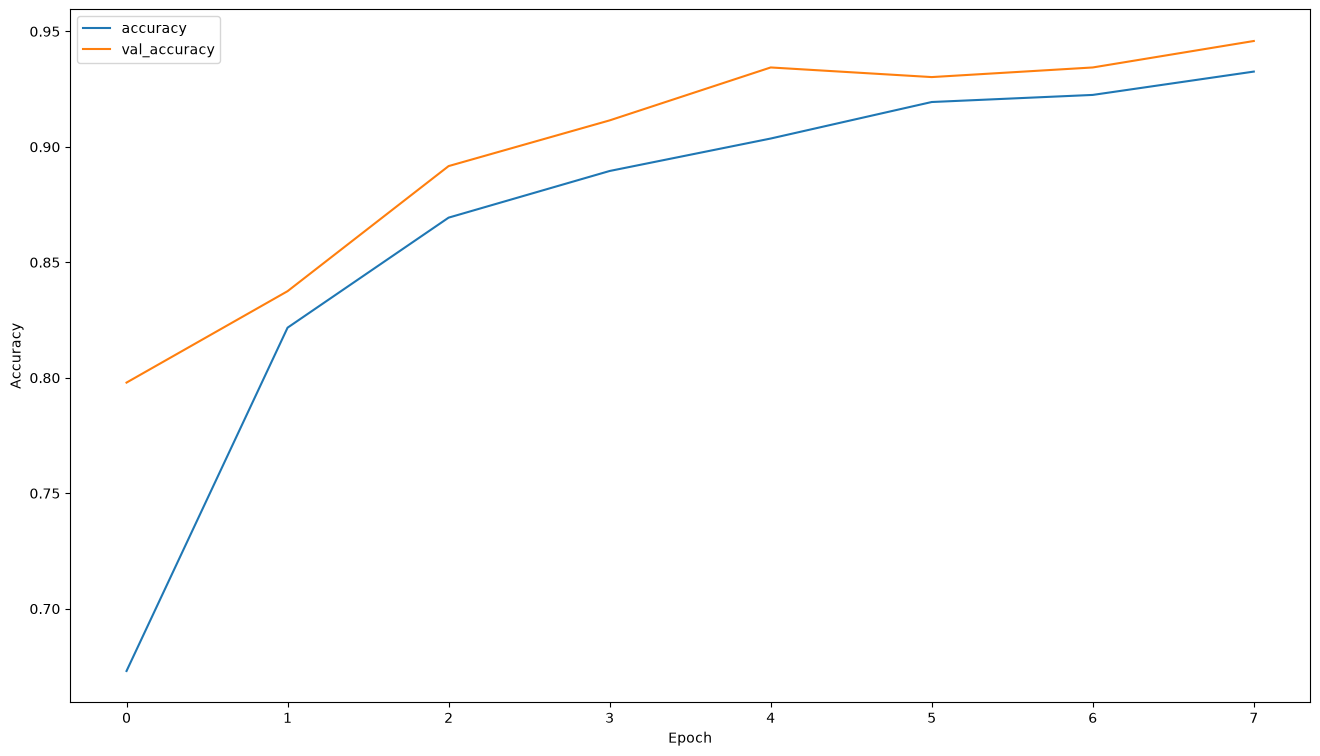

In [15]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
epoch_s = range(len(acc))

plt.figure(figsize=(16, 9))
plt.plot(epoch_s, acc)
plt.plot(epoch_s, val_acc)
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend(['accuracy', 'val_accuracy'])
plt.show()